# Duka Electronics H1 Board Visual Report

ADEN AHMED MOHAMED — Cohort 1M DEVIS

Sales period: 1 January–29 June 2026, synthetic seed-2026 orders.

## Storyboard: audience, decision, Big Idea and SCR

**Audience:** nontechnical Duka board members reading on phones before the H1 review.  
**Decision:** where to focus H2 commercial investigation and marketing allocation.  
**Big Idea:** Protect Nairobi’s 36.4% revenue base and investigate the roughly quarter-sized Q2 declines in Mombasa and Nakuru before reallocating H2 budget.

**Situation:** The 1,000 generated H1 orders produce KES 71.79 million, with Nairobi contributing over a third.  
**Complication:** Mombasa and Nakuru both fall by about a quarter from Q1 to Q2 while other branches grow; June/Q2 have partial date coverage.  
**Resolution:** Review the two declining branches’ product/channel mix and comparable-period performance, protect Nairobi, and test targeted actions before committing additional spending.

**Evidence plan:** branch revenue shows concentration; Q1/Q2 branch comparison locates weakness; monthly revenue shows timing; product revenue highlights dependence on Laptops; channel revenue shows routes to market. Each panel answers one question, has its own source and units, and supports the allocation discussion. The report uses five vertically stacked charts so phone readers can scroll and zoom without a 12-colour legend.

In [1]:
from pathlib import Path
import runpy
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
%matplotlib inline

if not Path("duka_sales.csv").exists():
    runpy.run_path("generate_data.py")
sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales.quantity * sales.unit_price
sales["month"] = sales.order_date.dt.to_period("M").astype(str)
sales["quarter"] = np.where(sales.order_date.dt.month.le(3), "Q1", "Q2")
Path("figures").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)
RED, GREEN, GREY, DARK = "#8E0000", "#0BA184", "#B7BDC5", "#273344"
total = sales.revenue.sum()
branch = sales.groupby("branch").revenue.sum().sort_values(ascending=False)
product = sales.groupby("product").revenue.sum().sort_values(ascending=False)
channel = sales.groupby("channel").revenue.sum().sort_values(ascending=False)
monthly = sales.groupby("month").revenue.sum()
quarter = sales.pivot_table(index="branch", columns="quarter", values="revenue", aggfunc="sum")
quarter["growth_pct"] = (quarter.Q2 / quarter.Q1 - 1) * 100
display(quarter.round(2))
print("Last recorded order:", sales.order_date.max().date())
print(f"Total KES {total:,.0f}; orders {sales.order_id.nunique():,}; AOV KES {sales.revenue.mean():,.2f}")

quarter,Q1,Q2,growth_pct
branch,,,
Eldoret,3538500,5305700,49.94
Kisumu,5008900,5859200,16.98
Mombasa,8023100,5980600,-25.46
Nairobi,12484700,13621400,9.10
Nakuru,6900200,5070200,-26.52


Last recorded order: 2026-06-29
Total KES 71,792,500; orders 1,000; AOV KES 71,792.50


## Chart makeover: before and after

The default chart below deliberately uses unsorted vertical bars, a descriptive title and default axes. The redesign ranks products, uses horizontal labels, highlights only the leader, removes redundant spines, labels values directly and calculates an insight title from the data. Both use an honest zero baseline; the message stays the same, but its evidence becomes easier to read.

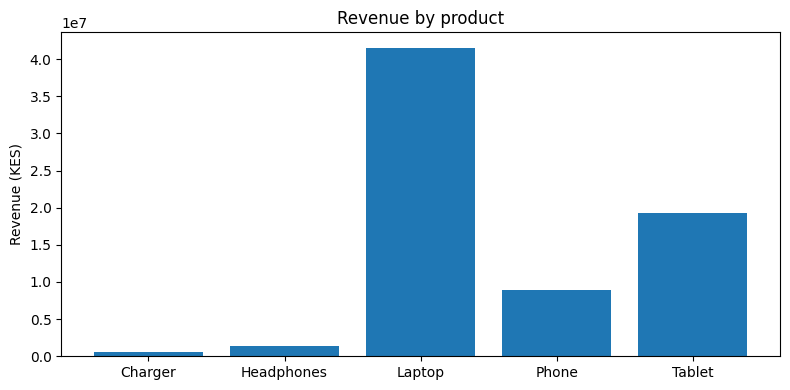

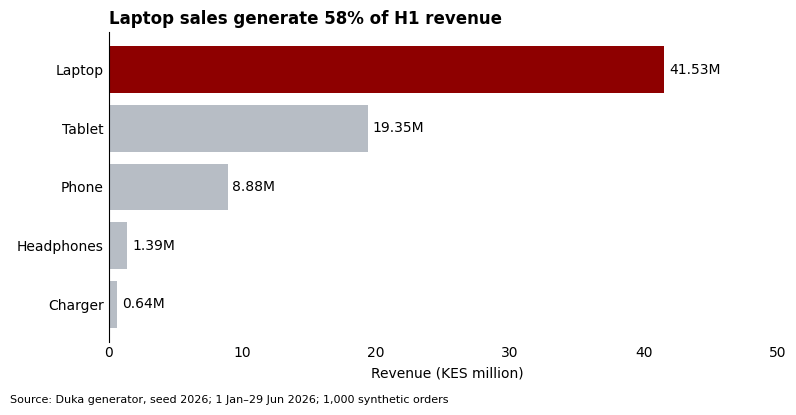

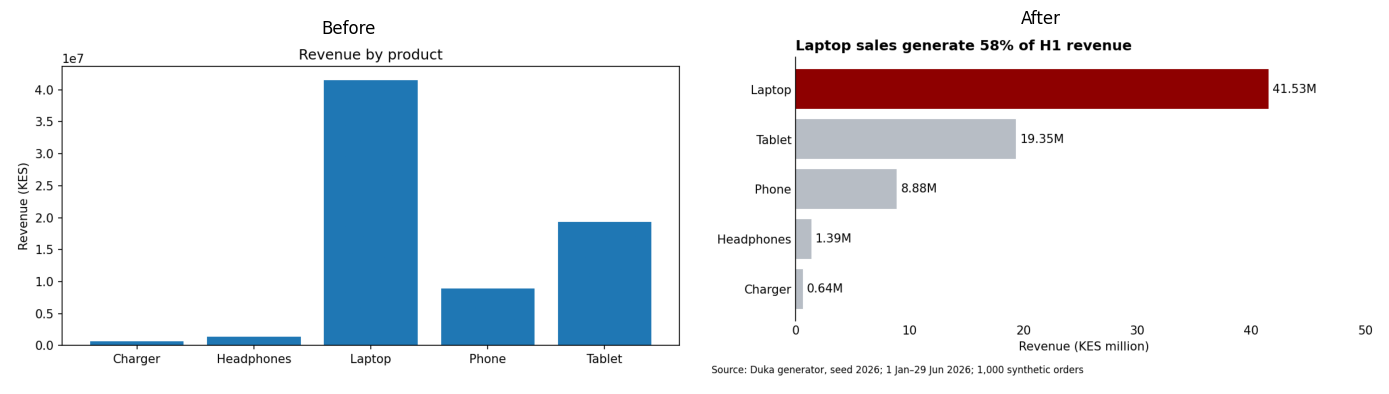

In [2]:
default_product = sales.groupby("product").revenue.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(default_product.index, default_product.values)
ax.set_title("Revenue by product")
ax.set_ylabel("Revenue (KES)")
fig.tight_layout()
fig.savefig("figures/before.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
colours = [RED] + [GREY]*(len(product)-1)
ax.barh(product.index, product/1e6, color=colours)
ax.invert_yaxis()
ax.set_xlim(0, product.max()/1e6*1.22)
ax.set_xlabel("Revenue (KES million)")
ax.set_title(f"{product.index[0]} sales generate {product.iloc[0]/total:.0%} of H1 revenue", loc="left", fontweight="bold")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="both", length=0)
for row, value in enumerate(product):
    ax.text(value/1e6+.35, row, f"{value/1e6:.2f}M", va="center")
fig.text(.01, -.02, "Source: Duka generator, seed 2026; 1 Jan–29 Jun 2026; 1,000 synthetic orders", fontsize=8)
fig.tight_layout()
fig.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["before", "after"]):
    ax.imshow(plt.imread(f"figures/{name}.png")); ax.axis("off"); ax.set_title(name.title())
fig.tight_layout()
plt.show()

**Design changes:** Sorting makes rank visible; horizontal bars fit product names on a phone; grey plus PLP redberry concentrates attention on Laptops; direct labels remove the need to estimate exact values; the calculated headline states the 58% contribution; missing top/right/bottom borders reduce decoration without removing units or a zero baseline. Source and period allow the chart to stand alone. These exported comparisons are `figures/before.png` and `figures/after.png`.

## One-page board report

Five panels with calculated insight titles, KES-million axes and per-panel sources. Q1 and Q2 bars share a zero baseline and legend; only the two declining branches are coloured. Q2 contains April–29 June, so the decline must be investigated using comparable dates before attributing it to demand or approving a budget change.

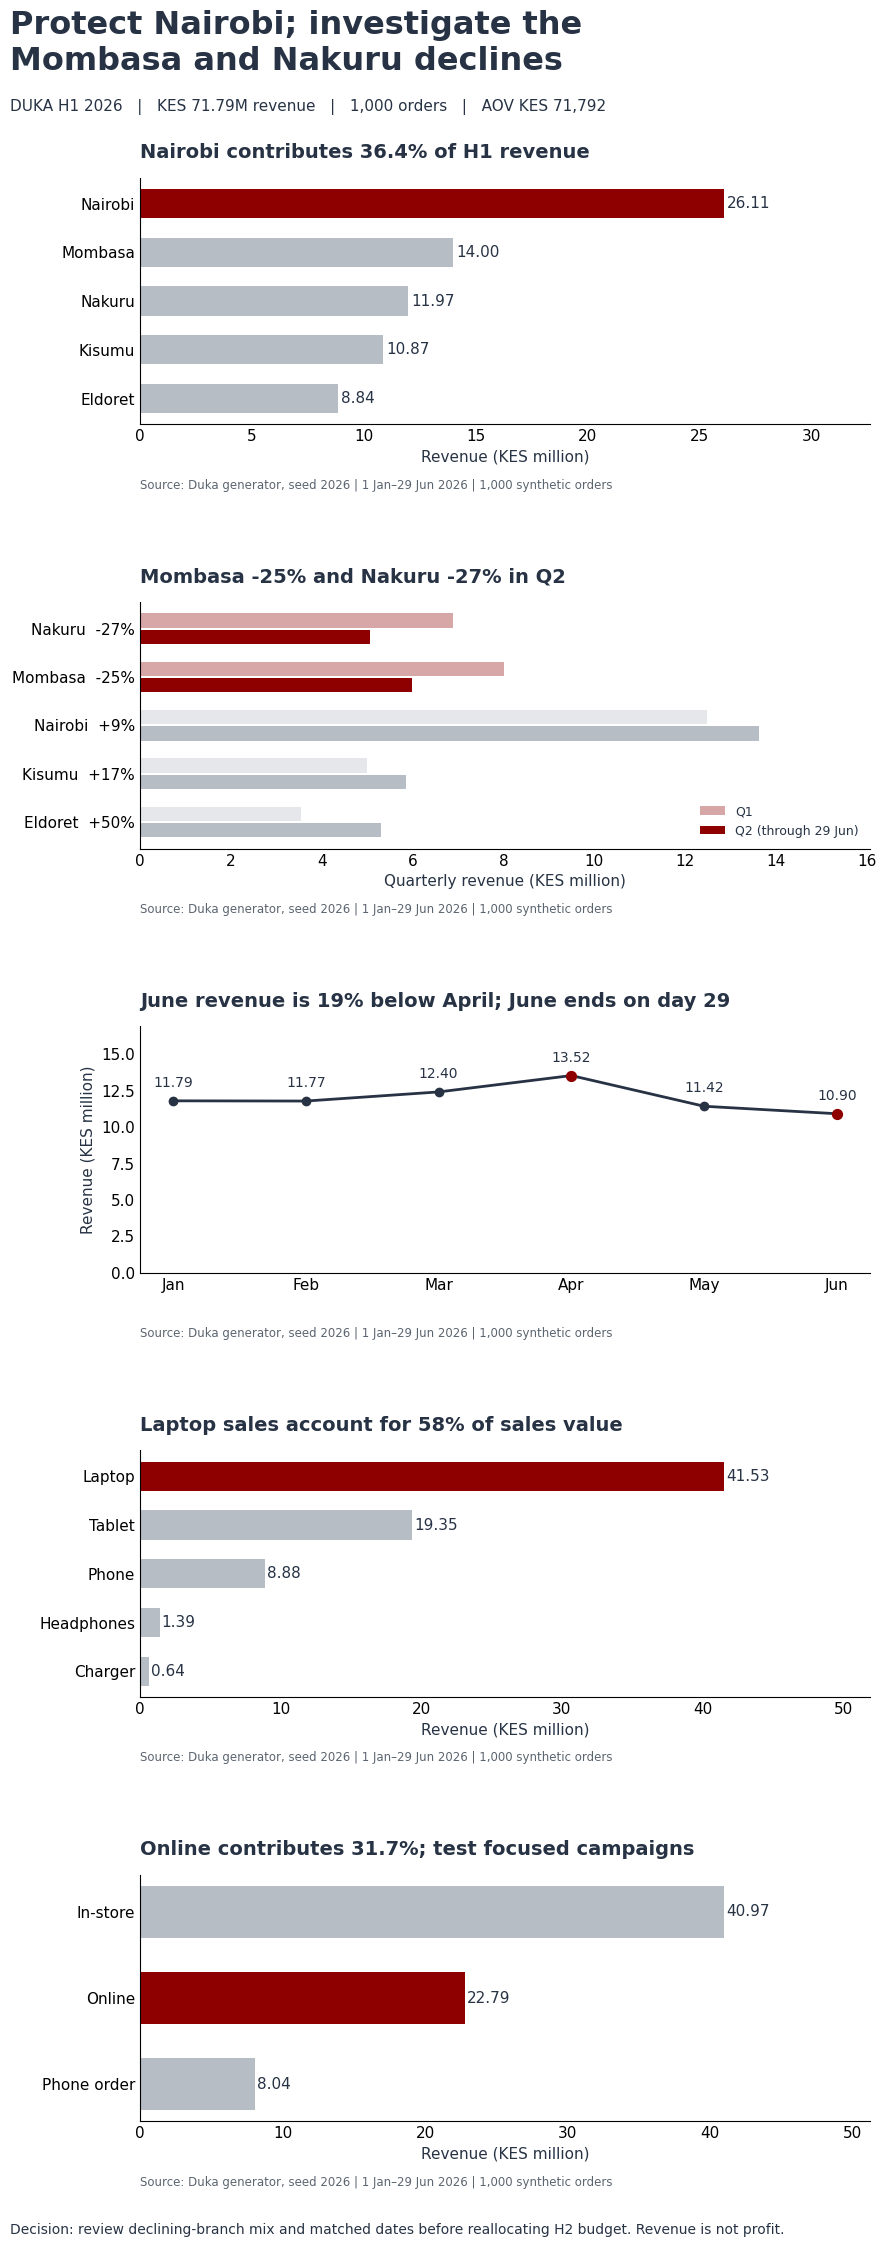

Saved reports/duka_board_report.png and outputs/duka_dashboard_data.csv


In [3]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titleweight": "bold", "axes.labelcolor": DARK, "text.color": DARK})
fig, axes = plt.subplots(5, 1, figsize=(10, 23))
fig.subplots_adjust(top=.90, bottom=.055, left=.19, right=.92, hspace=.72)
fig.text(.06, .973, "Protect Nairobi; investigate the\nMombasa and Nakuru declines", fontsize=23, fontweight="bold", va="top")
fig.text(.06, .929, f"DUKA H1 2026   |   KES {total/1e6:.2f}M revenue   |   1,000 orders   |   AOV KES {sales.revenue.mean():,.0f}", fontsize=11)
source = "Source: Duka generator, seed 2026 | 1 Jan–29 Jun 2026 | 1,000 synthetic orders"
def finish(ax, title):
    ax.set_title(title, loc="left", fontsize=14, pad=14)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", length=0)
    ax.text(0, -.26, source, transform=ax.transAxes, fontsize=8.5, color="#5B6570")

def bars(ax, series, highlighted, title):
    ax.barh(series.index, series/1e6, color=[RED if label in highlighted else GREY for label in series.index], height=.6)
    ax.invert_yaxis(); ax.set_xlim(0, series.max()/1e6*1.25)
    ax.set_xlabel("Revenue (KES million)")
    for row, value in enumerate(series):
        ax.text(value/1e6+.15, row, f"{value/1e6:.2f}", va="center", fontsize=11)
    finish(ax, title)

bars(axes[0], branch, [branch.index[0]], f"{branch.index[0]} contributes {branch.iloc[0]/total:.1%} of H1 revenue")

ax = axes[1]
q = quarter.sort_values("growth_pct")
y = np.arange(len(q)); colours = [RED if name in ["Mombasa", "Nakuru"] else GREY for name in q.index]
ax.barh(y-.17, q.Q1/1e6, height=.3, color=colours, alpha=.35, label="Q1")
ax.barh(y+.17, q.Q2/1e6, height=.3, color=colours, label="Q2 (through 29 Jun)")
ax.set_yticks(y, [f"{name}  {q.loc[name,'growth_pct']:+.0f}%" for name in q.index])
ax.invert_yaxis();ax.set_xlim(0, q[["Q1", "Q2"]].to_numpy().max()/1e6*1.18)
ax.set_xlabel("Quarterly revenue (KES million)")
ax.legend(frameon=False, loc="lower right", fontsize=9)
finish(ax, f"Mombasa {quarter.loc['Mombasa','growth_pct']:.0f}% and Nakuru {quarter.loc['Nakuru','growth_pct']:.0f}% in Q2")

ax = axes[2]
ax.plot(np.arange(len(monthly)), monthly/1e6, color=DARK, linewidth=2, marker="o")
peak_index=int(np.argmax(monthly.values));last_index=len(monthly)-1
ax.scatter([peak_index,last_index], [monthly.iloc[peak_index]/1e6,monthly.iloc[-1]/1e6], color=RED,zorder=3,s=50)
ax.set_xticks(np.arange(len(monthly)),pd.to_datetime(monthly.index).strftime("%b"))
ax.set_ylim(0, monthly.max()/1e6*1.25);ax.set_ylabel("Revenue (KES million)")
for index,value in enumerate(monthly):ax.annotate(f"{value/1e6:.2f}",(index,value/1e6),xytext=(0,10),textcoords="offset points",ha="center",fontsize=10)
fall=(monthly.iloc[-1]/monthly.iloc[peak_index]-1)*100
finish(ax, f"June revenue is {abs(fall):.0f}% below April; June ends on day 29")

bars(axes[3], product, [product.index[0]], f"{product.index[0]} sales account for {product.iloc[0]/total:.0%} of sales value")
bars(axes[4], channel, ["Online"], f"Online contributes {channel.loc['Online']/total:.1%}; test focused campaigns")
fig.text(.06,.006,"Decision: review declining-branch mix and matched dates before reallocating H2 budget. Revenue is not profit.",fontsize=10)
fig.savefig("reports/duka_board_report.png", dpi=180, facecolor="white")
plt.show()
# Dataset prepared for a real Looker Studio dashboard; ISO dates and numeric revenue.
dashboard_data = sales[["order_id", "order_date", "branch", "product", "quantity", "channel", "unit_price", "revenue"]].copy()
dashboard_data.to_csv("outputs/duka_dashboard_data.csv", index=False, date_format="%Y-%m-%d")
print("Saved reports/duka_board_report.png and outputs/duka_dashboard_data.csv")

## Dashboard verification targets

The dashboard data exports 1,000 rows with ISO order_date and numeric revenue. A live dashboard must show revenue KES 71,792,500, 1,000 distinct orders and average order value KES 71,792.50 before filtering. Use monthly revenue, branch and product breakdowns, date-range and channel filters, then test Online alone against KES 22,786,100 and 320 distinct orders. Dashboard publication and authentic screenshots are tracked in dashboard.md; they are not replaced by the static board report.

## Review and limitations

The original generator is unchanged and all titles above use recomputed values. The 180-day sample ends on 29 June; Q1 has 90 calendar days and the generated Q2 window has 89, so raw quarterly totals are not equal-exposure performance estimates. No prior-year data, discounts, margin, stock availability or campaign spend is supplied, so the story supports investigation rather than a causal diagnosis or guaranteed return on marketing. This synthetic exercise cannot establish real branch performance.